STUDI KASUS DATA DEATH CLEAN

In [415]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

# Asumsi data telah dibaca
df = pd.read_csv('death_clean.csv')

df.head()


,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...


TRANSFORM & SPLIT DATA

In [416]:
x = df[['Cause', 'Type']]
y = df[['Total Deaths']]

x_encoded = pd.get_dummies(x, columns=['Cause', 'Type'])

scaler = StandardScaler()
y_norm = scaler.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_encoded, y_norm, test_size=0.3, random_state=42)

MODEL DECISION TREE

In [417]:
model = DecisionTreeRegressor()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([ 0.10012888, -0.15100538, -0.33083475, -0.24092006, -0.00426679,
       -0.00426679, -0.15100538, -0.54945084, -0.50915294, -0.3872518 ,
       -0.54945084,  2.5076484 , -0.15100538,  0.34616993,  1.54503237,
       -0.15100538, -0.54945084,  2.5076484 , -0.49655985, -0.3872518 ,
       -0.39077787,  0.83981917,  0.95970542, -0.48833236, -0.15100538,
       -0.54945084, -0.54945084, -0.41122905, -0.0268095 , -0.0268095 ,
       -0.49068307, -0.54945084, -0.54945084, -0.15100538, -0.38654659,
       -0.15100538,  2.5076484 ,  0.83981917, -0.12749827, -0.12749827,
        0.10012888, -0.54945084, -0.47892952, -0.15100538, -0.38654659,
        1.24884283, -0.00426679, -0.0268095 , -0.4295646 , -0.0268095 ,
       -0.39077787, -0.43873237, -0.54945084, -0.54945084, -0.48363094,
       -0.53816743, -0.00426679, -0.00426679,  0.053827  ,  2.91314599,
       -0.54945084, -0.54945084, -0.45424706,  0.8891841 , -0.24092006,
        2.5076484 ,  0.44725049,  1.24884283, -0.00426679,  0.05

R SCORE

In [418]:
score = model.score(x_test, y_test)
print("Decision Tree Score:", score)

Decision Tree Score: 0.7503779883924386


FEATURE IMPORTANCE

In [419]:
importances = model.feature_importances_

feature_names = x_train.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

importance_df = importance_df.sort_values(by='Importance', ascending=False)
importance_df.head()

,Feature,Importance
0,Cause_AIDS,0.152764
24,Cause_Demam Berdarah Dengue (DBD),0.125555
34,Cause_Gangguan saluran napas lainnya yang berh...,0.086984
119,"Cause_Malformasi, Deformasi Kongenital & Kelai...",0.076848
108,Cause_Kronis Filariasis,0.063348


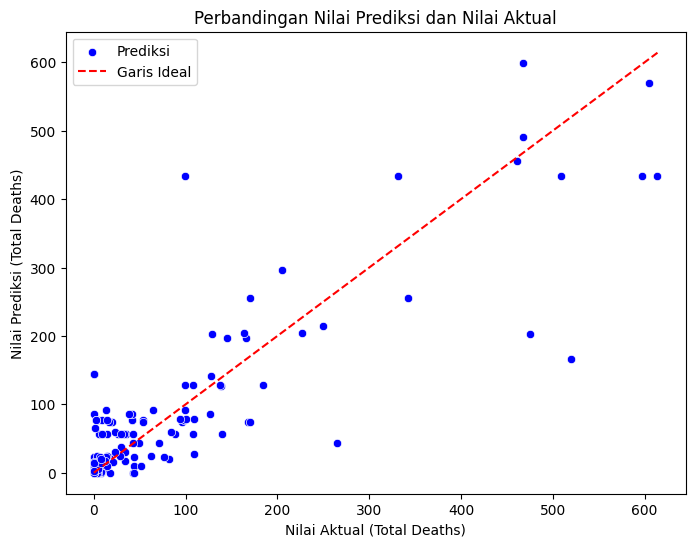

In [420]:
comparison_df = pd.DataFrame({
    'Actual': scaler.inverse_transform(y_test.reshape(-1, 1)).ravel(),
    'Predicted': scaler.inverse_transform(y_pred.reshape(-1, 1)).ravel()
})

plt.figure(figsize=(8, 6))
sns.scatterplot(x=comparison_df['Actual'], y=comparison_df['Predicted'], color='blue', label='Prediksi')
plt.plot([comparison_df['Actual'].min(), comparison_df['Actual'].max()], 
         [comparison_df['Actual'].min(), comparison_df['Actual'].max()], 
         color='red', linestyle='--', label='Garis Ideal')

plt.title('Perbandingan Nilai Prediksi dan Nilai Aktual')
plt.xlabel('Nilai Aktual (Total Deaths)')
plt.ylabel('Nilai Prediksi (Total Deaths)')
plt.legend()
plt.show()


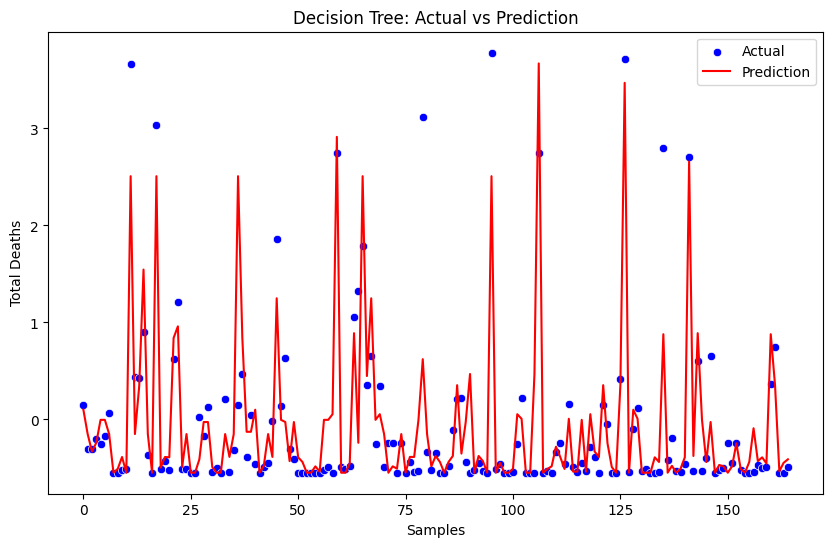

In [421]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=range(len(y_test)), y=y_test, color='blue', label='Actual')
sns.lineplot(x=range(len(y_test)), y=y_pred, color='red', label='Prediction')

plt.xlabel('Samples')
plt.ylabel('Total Deaths')
plt.title('Decision Tree: Actual vs Prediction')
plt.legend()
plt.show()

In [428]:
from graphviz import Digraph

dot = Digraph()
dot.node('A', 'Node A')
dot.node('B', 'Node B')
dot.edge('A', 'B', 'Edge from A to B')

dot.render('output_graph', format='png')

'output_graph.png'

GRAPHVIZ

In [422]:
import graphviz
from io import StringIO
from sklearn.tree import export_graphviz

x_encoded.columns = x_encoded.columns.str.replace('[^a-zA-Z0-9]', '_', regex=True)

dot_data = StringIO()
export_graphviz(model, out_file=dot_data, 
                feature_names=x_encoded.columns,
                filled=True, rounded=True, special_characters=False)

graph = graphviz.Source(dot_data.getvalue())

graph.render("decision_tree", format='pdf')

graph.view()

'decision_tree.pdf'

In [423]:
test_data = pd.DataFrame({
    'Cause': ['Gempa Bumi', 'Banjir', 'Kebakaran', 'Tsunami', 'Angin Puting Beliung', 'Tanah Longsor'],
    'Type': ['Bencana Alam'] * 6
})

test_data_encoded = pd.get_dummies(test_data, columns=['Cause', 'Type'])

reference_columns = pd.get_dummies(x[['Cause', 'Type']]).columns
test_data_encoded = test_data_encoded.reindex(columns=reference_columns, fill_value=0)

predictions = model.predict(test_data_encoded)
predictions = scaler.inverse_transform(predictions.reshape(-1, 1)).ravel().astype(int)
test_data['Total Deaths'] = predictions
test_data

,Cause,Type,Total Deaths
0,Gempa Bumi,Bencana Alam,92
1,Banjir,Bencana Alam,56
2,Kebakaran,Bencana Alam,24
3,Tsunami,Bencana Alam,144
4,Angin Puting Beliung,Bencana Alam,14
5,Tanah Longsor,Bencana Alam,74


DECISSION TREE CLASSIFIER

In [424]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Membuat dataset buatan
np.random.seed(42)
data_size = 100
age = np.random.randint(18, 60, size=data_size)  # Usia (18-60 tahun)
income = np.random.randint(20000, 120000, size=data_size)  # Pendapatan tahunan (20k - 120k)
education = np.random.randint(1, 5, size=data_size)  # Tingkat pendidikan (1-4)

# Target: Apakah seseorang membeli produk (0: Tidak, 1: Ya)
purchase = np.random.randint(0, 2, size=data_size)

# Membuat DataFrame
df = pd.DataFrame({
    'Age': age,
    'Income': income,
    'Education': education,
    'Purchase': purchase
})

# Memisahkan fitur dan target
x = df[['Age', 'Income', 'Education']]
y = df['Purchase']

# Normalisasi fitur (opsional)
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

# Membagi dataset menjadi set pelatihan dan pengujian
x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.3, random_state=42)

# Inisialisasi DecisionTreeClassifier
model = DecisionTreeClassifier(random_state=42)

# Melatih model
model.fit(x_train, y_train)

# Membuat prediksi
y_pred = model.predict(x_test)

# Mengukur akurasi
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi: {accuracy * 100:.2f}%")


Akurasi: 36.67%


DECISSION TREE REGRESSOR

In [425]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

df = pd.DataFrame({
    'Experience': np.random.randint(0, 6, size=50),
    'Education': np.random.randint(1, 4, size=50),
    'Salary': np.random.randint(2000000, 11000000, size=50)
})

x = df[['Experience', 'Education']]
y = df[['Salary']]

scaler_x = StandardScaler()
x_scaled = scaler_x.fit_transform(x)

scaler_y = StandardScaler()
y_norm = scaler_y.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_scaled, y_norm, test_size=0.3, random_state=42)

model = DecisionTreeRegressor()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

importances = model.feature_importances_

feature_names = x.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

importance_df = importance_df.sort_values(by='Importance', ascending=False)

rf_score = model.score(x_test, y_test)

new_data = pd.DataFrame({
    'Experience': [1, 2, 5],
    'Education': [1, 3, 2]
})

prediction = model.predict(new_data)
prediction


/Users/suniantara/Documents/Project/Python/.venv/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(


array([-1.4022476 ,  0.39385437,  0.39385437])

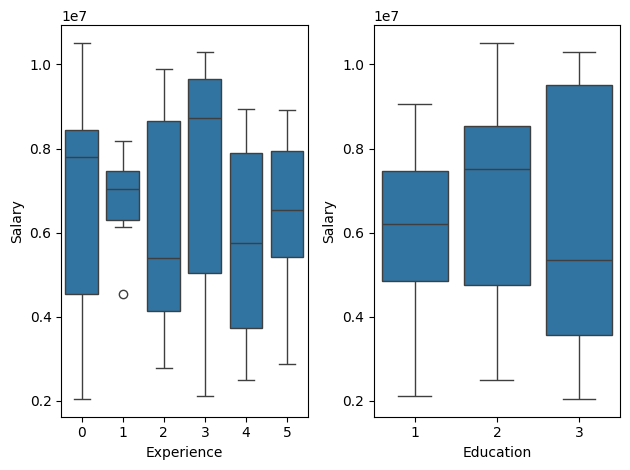

In [426]:
fig, axes = plt.subplots(1, 2) # (baris, kolom)

sns.boxplot(x='Experience', y='Salary', data=df, ax = axes[0])
axes[0].set_xlabel('Experience')

sns.boxplot(x='Education', y='Salary', data=df, ax = axes[1])
axes[1].set_xlabel('Education')

fig.tight_layout()
plt.show()

'output_graph.png'